# Biologically Inspired Computation — Coursework
### Generic Multilayer Perceptron (MLP) trained by Particle Swarm Optimisation (PSO)

This notebook implements the design in `CW-design.pdf`:

- **MLP component** (`src/mlp/`): `Layer`, `Network`, activation/loss hierarchies, built via the `MLPBuilder` (**Builder** pattern).
- **PSO component** (`src/pso/`): `Particle`, `Population`, informant selection via the `InformantSelectionStrategy` (**Strategy** pattern — Random vs Nearest-Neighbour).
- **Adapter** (`src/adapter/`): `MLPFitnessAdapter` connects PSO's generic `FitnessFunction` interface to the MLP, so the two components stay fully independent (PSO never knows it's optimising a neural network).

Run all cells top to bottom. Each section has a short explanation before the code.

## 0. Setup

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from src.mlp.builder import MLPBuilder
from src.adapter.mlp_fitness_adapter import MLPFitnessAdapter
from src.pso.informant_strategy import RandomInformantSelection, NearestNeighbourInformantSelection
from src.pso.population import Population

np.random.seed(0)
plt.rcParams["figure.figsize"] = (7, 4)


## 1. Load and prepare the dataset

Using scikit-learn's Iris dataset as a placeholder — swap `load_dataset()`
below for your team's actual coursework dataset. Everything downstream
(builder config, PSO setup, metrics) stays the same regardless of dataset,
because the MLP and PSO components are generic.

In [2]:
def load_dataset():
    data = load_iris()
    return data.data, data.target

X, y = load_dataset()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Fit preprocessing on training data only.
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

encoder = OneHotEncoder(sparse_output=False)
y_train_oh = encoder.fit_transform(y_train.reshape(-1, 1))

print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("classes:", encoder.categories_[0])


X_train: (120, 4) X_test: (30, 4)
classes: [0 1 2]


## 2. Configure and build the MLP (Builder pattern)

`MLPBuilder` takes the dataset + a hyperparameter dict and returns a ready
`Network` + matching `Loss` object — no manual `Layer` wiring required.

In [3]:
builder = MLPBuilder()
builder.set_dataset(X_train, y_train_oh)
builder.set_configuration({
    "hidden_layers": [8, 5],
    "activations": ["tanh", "sigmoid"],
    "task": "multiclass_classification",
})
network, loss = builder.build()

print("Total trainable parameters (PSO search dimension):", network.count_parameters())
for i, layer in enumerate(network.layers):
    print(f"  Layer {i}: {layer.input_size} -> {layer.output_size}, "
          f"activation={layer.activation.__class__.__name__}")


Total trainable parameters (PSO search dimension): 103
  Layer 0: 4 -> 8, activation=Tanh
  Layer 1: 8 -> 5, activation=Sigmoid
  Layer 2: 5 -> 3, activation=Softmax


## 3. Connect PSO <-> MLP (Adapter pattern)

`MLPFitnessAdapter` implements `FitnessFunction.evaluate(position)`: it installs
a candidate parameter vector into the network, runs a forward pass on the
**training data only**, and returns the scalar loss. This is the *only*
place that knows about both PSO and the MLP.

In [4]:
fitness = MLPFitnessAdapter(network=network, loss=loss, X_train=X_train, y_train=y_train_oh)
print(fitness.evaluate(network.get_parameters()))  # loss at the random initial weights


1.0994151091820283


## 4. Configure and run PSO (Strategy pattern for informants)

`Population.optimise()` runs the loop from the spec's pseudocode: initialise,
evaluate, then repeatedly reassign informants, move every particle, and
re-evaluate. Informants are chosen fresh every iteration by whichever
`InformantSelectionStrategy` we pass in.

In [5]:
informant_strategy = NearestNeighbourInformantSelection()
# Alternative: informant_strategy = RandomInformantSelection()

population = Population(
    fitness_function=fitness,
    informant_strategy=informant_strategy,
    num_particles=30,
    num_informants=3,
    num_iterations=150,
    dimension=network.count_parameters(),
    inertia_weight=0.7,
    cognitive_coefficient=1.5,
    social_coefficient=1.5,
    seed=1,
)

best_position, best_fitness = population.optimise()
print("Best training loss:", best_fitness)


Best training loss: 0.0865032229823946


## 5. Convergence plot

The global-best fitness should fall monotonically (PSO only updates the
global best when it strictly improves) and flatten out as the swarm
converges.

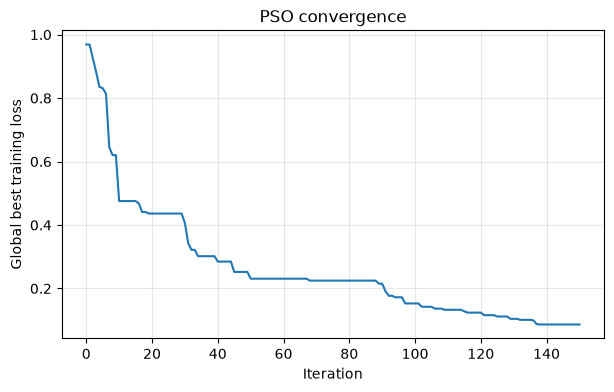

In [6]:
plt.plot(population.fitness_history)
plt.xlabel("Iteration")
plt.ylabel("Global best training loss")
plt.title("PSO convergence")
plt.grid(alpha=0.3)
plt.show()


## 6. Install the best parameters and evaluate on the held-out test set

The test set was never touched during PSO optimisation (the adapter only
ever saw `X_train`/`y_train`).

In [7]:
network.set_parameters(best_position)
predictions = network.predict(X_test)
predicted_labels = np.argmax(predictions, axis=1)

accuracy = accuracy_score(y_test, predicted_labels)
precision = precision_score(y_test, predicted_labels, average="macro", zero_division=0)
recall = recall_score(y_test, predicted_labels, average="macro", zero_division=0)
f1 = f1_score(y_test, predicted_labels, average="macro", zero_division=0)

print(f"Test accuracy:  {accuracy:.3f}")
print(f"Test precision: {precision:.3f}")
print(f"Test recall:    {recall:.3f}")
print(f"Test F1-score:  {f1:.3f}")


Test accuracy:  0.967
Test precision: 0.970
Test recall:    0.967
Test F1-score:  0.967


## 7. Experiment: Random vs Nearest-Neighbour informant selection

The spec asks us to compare informant-selection strategies. We re-run PSO
from scratch with each strategy (same MLP architecture, same PSO
hyperparameters, same random seed per run) and compare convergence speed
and final training loss.

In [8]:
def run_pso(strategy, seed):
    builder = MLPBuilder()
    builder.set_dataset(X_train, y_train_oh)
    builder.set_configuration({
        "hidden_layers": [8, 5],
        "activations": ["tanh", "sigmoid"],
        "task": "multiclass_classification",
    })
    net, l = builder.build()
    fit = MLPFitnessAdapter(network=net, loss=l, X_train=X_train, y_train=y_train_oh)
    pop = Population(
        fitness_function=fit,
        informant_strategy=strategy,
        num_particles=30,
        num_informants=3,
        num_iterations=150,
        dimension=net.count_parameters(),
        inertia_weight=0.7,
        cognitive_coefficient=1.5,
        social_coefficient=1.5,
        seed=seed,
    )
    best_pos, best_fit = pop.optimise()
    return net, pop, best_pos, best_fit

results = {}
for name, strategy in [("random", RandomInformantSelection()),
                        ("nearest_neighbour", NearestNeighbourInformantSelection())]:
    net, pop, best_pos, best_fit = run_pso(strategy, seed=1)
    net.set_parameters(best_pos)
    preds = np.argmax(net.predict(X_test), axis=1)
    acc = accuracy_score(y_test, preds)
    results[name] = {"history": pop.fitness_history, "best_fit": best_fit, "test_accuracy": acc}
    print(f"{name:18s} best training loss={best_fit:.4f}  test accuracy={acc:.3f}")


random             best training loss=0.3526  test accuracy=0.867


nearest_neighbour  best training loss=0.0865  test accuracy=0.967


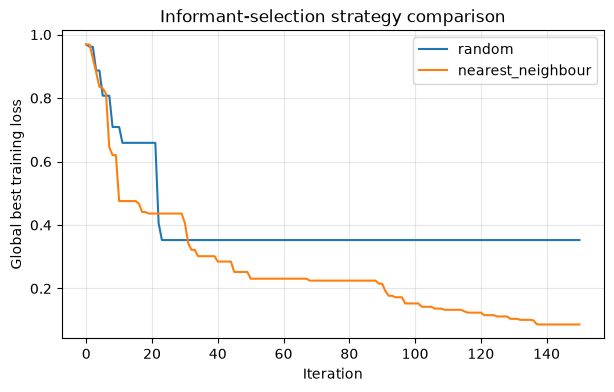

In [9]:
plt.figure(figsize=(7, 4))
for name, r in results.items():
    plt.plot(r["history"], label=name)
plt.xlabel("Iteration")
plt.ylabel("Global best training loss")
plt.title("Informant-selection strategy comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 8. Experiment: hyperparameter comparison (population size)

A second axis to compare, as required by the spec: how does swarm size
affect convergence speed and final solution quality?

num_particles= 10  best training loss=0.1675


num_particles= 30  best training loss=0.0865


num_particles= 60  best training loss=0.0856


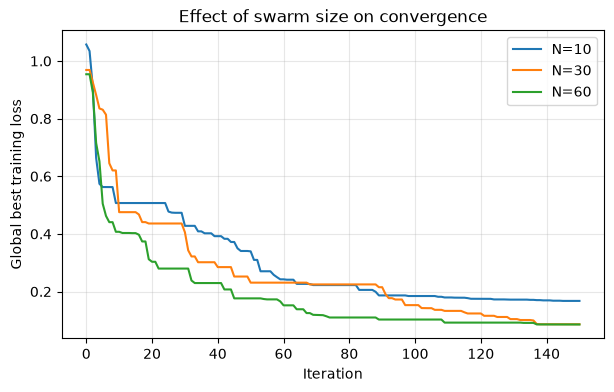

In [10]:
pop_sizes = [10, 30, 60]
size_results = {}
for n in pop_sizes:
    builder = MLPBuilder()
    builder.set_dataset(X_train, y_train_oh)
    builder.set_configuration({
        "hidden_layers": [8, 5],
        "activations": ["tanh", "sigmoid"],
        "task": "multiclass_classification",
    })
    net, l = builder.build()
    fit = MLPFitnessAdapter(network=net, loss=l, X_train=X_train, y_train=y_train_oh)
    k = min(3, n - 1)
    pop = Population(
        fitness_function=fit,
        informant_strategy=NearestNeighbourInformantSelection(),
        num_particles=n,
        num_informants=k,
        num_iterations=150,
        dimension=net.count_parameters(),
        inertia_weight=0.7,
        cognitive_coefficient=1.5,
        social_coefficient=1.5,
        seed=1,
    )
    _, best_fit = pop.optimise()
    size_results[n] = pop.fitness_history
    print(f"num_particles={n:3d}  best training loss={best_fit:.4f}")

plt.figure(figsize=(7, 4))
for n, history in size_results.items():
    plt.plot(history, label=f"N={n}")
plt.xlabel("Iteration")
plt.ylabel("Global best training loss")
plt.title("Effect of swarm size on convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 9. Summary

Report at minimum, per the coursework spec:
- Best training loss (section 6 / 7)
- Test accuracy, precision, recall, F1 (section 6)
- PSO convergence behaviour (sections 5, 7, 8)
- Comparison between hyperparameters and informant-selection strategies (sections 7, 8)

Swap `load_dataset()` in section 1 for the team's final dataset, then re-run
all cells — nothing else needs to change, because `MLPBuilder`, `Population`
and `MLPFitnessAdapter` are dataset-agnostic.